Dato lo storico delle serie storiche di un insieme di titoli e dell'S&P 500, del prezzo del Brent e dei Treasury a 3 mesi, ti viene chiesto di:

1. trovare il portafoglio di Markowitz per un rendimento atteso annuo di 0,32;
2. tracciare la frontiera efficiente del portafoglio rischioso e la CAL assumendo un ulteriore asset privo di rischio (Treasury a 3 mesi);
3. trovare il portafoglio di Sharpe;

Come proxy del tasso privo di rischio, utilizzare la media dei Treasury a 3 mesi (colonna rf).

Utilizzando un modello a due fattori (S&P 500 e Brent), trovare:

1. i 10 migliori titoli su cui investire data la forte evidenza di una improvvisa diminuzione del prezzo del petrolio. Motivare la scelta (guardando anche al settore dei titoli, le informazioni possono essere recuperate tramite il modulo yfinance).

L'input è semplicemente un file di serie storiche.

In [106]:
!pip install yfinance
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [107]:
data = pd.read_csv("mark_sim.csv", index_col = "Date")
print(data.head())

                   AAP       ABMD        AOS        APA        ATO       CBOE  \
Date                                                                            
2014-03-27  120.386787  25.770000  20.311985  70.738632  38.335091  53.106892   
2014-03-28  121.125298  25.700001  20.594727  71.548737  38.443562  52.420502   
2014-03-31  122.922981  26.040001  20.653065  71.488411  39.328094  53.219734   
2014-04-01  123.651749  26.200001  20.810135  72.186493  39.169537  52.956448   
2014-04-02  123.272804  26.000000  21.007603  72.591560  39.553406  51.950348   

                 Brent        COP        CVX        DVA  ...        NOV  \
Date                                                     ...              
2014-03-27  101.279999  55.201248  84.980484  68.389999  ...  61.768215   
2014-03-28  101.669998  56.045704  85.579918  68.449997  ...  63.100582   
2014-03-31  101.580002  56.045704  85.875999  68.849998  ...  63.263077   
2014-04-01   99.739998  56.013840  85.940994  69.339996  

**Lascio solo gli asset rischiosi**, come suggerisce la teoria!

In [108]:
risky_data = data.copy()
risky_data.drop(['rf', 'Brent','SP500'], axis = 1, inplace = True) # togliamo rf, Brent e sp500;
print(risky_data)

                   AAP        ABMD        AOS        APA        ATO  \
Date                                                                  
2014-03-27  120.386787   25.770000  20.311985  70.738632  38.335091   
2014-03-28  121.125298   25.700001  20.594727  71.548737  38.443562   
2014-03-31  122.922981   26.040001  20.653065  71.488411  39.328094   
2014-04-01  123.651749   26.200001  20.810135  72.186493  39.169537   
2014-04-02  123.272804   26.000000  21.007603  72.591560  39.553406   
...                ...         ...        ...        ...        ...   
2018-03-20  111.739716  294.010010  61.713917  33.621437  75.099075   
2018-03-21  112.707970  292.309998  61.657558  35.317802  75.200729   
2018-03-22  109.312431  286.390015  60.558712  34.557678  75.006668   
2018-03-23  108.461113  283.989990  58.652164  34.307388  73.953239   
2018-03-26  112.306770  295.399994  60.323929  34.557678  75.487198   

                  CBOE        COP        CVX        DVA        DVN  ...  \
D

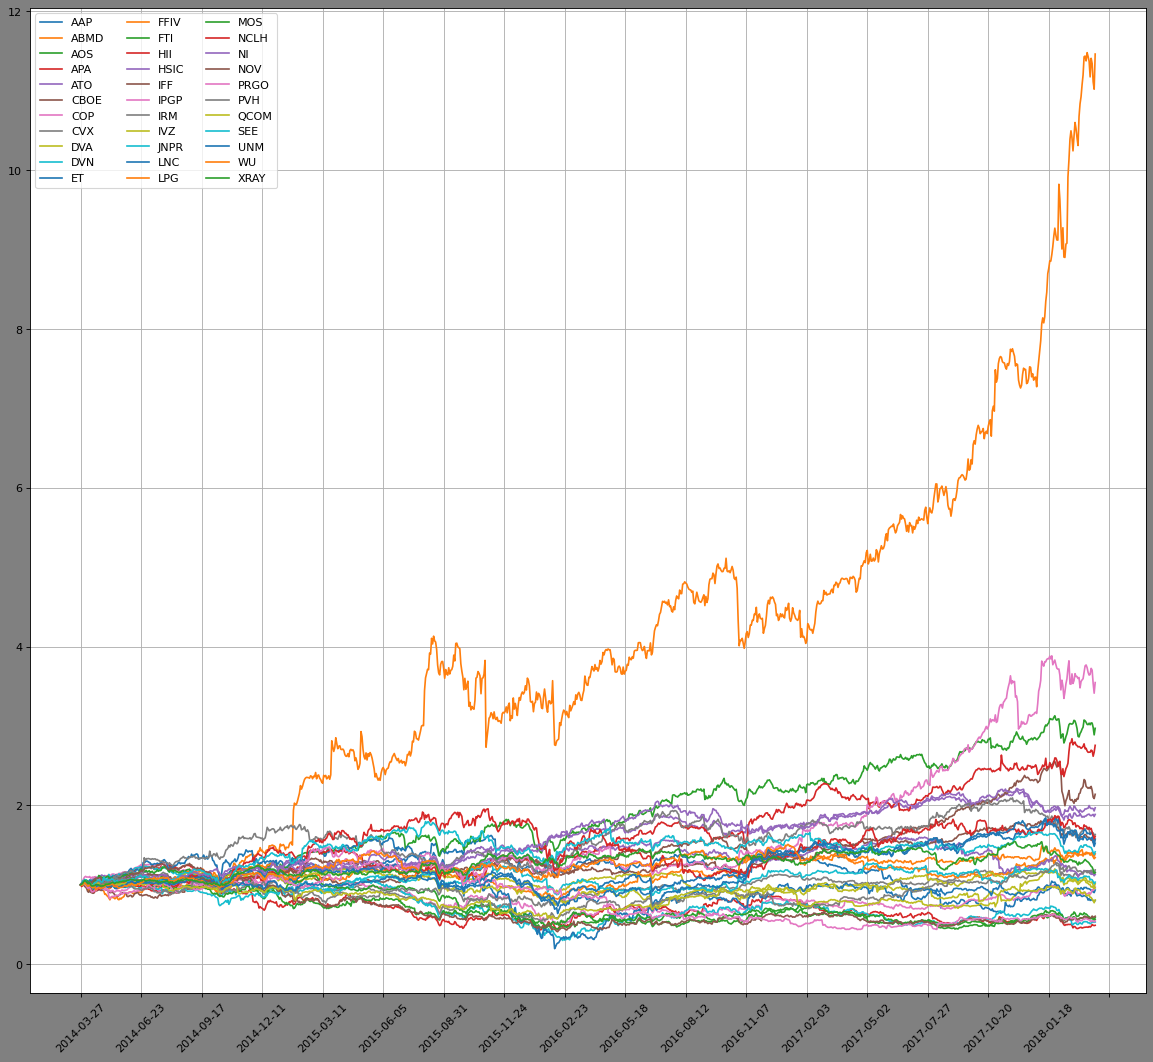

In [111]:
risky_d = risky_data/risky_data.iloc[0] # divisione per il primo prezzo cosi da partire tutti dalla
#stessa parte anche se gli asset sono diversi.

fig = plt.figure(figsize=(18,16), dpi=80, facecolor ='grey')
for i in risky_d.columns:
  plt.plot(risky_d[i], label=i)
plt.legend(ncol=3)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(20))
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

**lavorazione della serie risk-free**

In [112]:
rf_annualized = data["rf"].mean()
rf_annualized

np.float64(0.0040709099998185)

**Calcolo del rendimento giornaliero ma annualizzato**

Lineare

In [114]:
returns = data.pct_change().dropna()
#returns

ret_annualized = returns.mean()*252
ret_annualized # rendimento medio annualizzato di tutte le serie storiche presenti nel dataset originale

/tmp/ipykernel_2036/2650264378.py:1: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = data.pct_change().dropna()


,0
AAP,0.035274
ABMD,0.775363
AOS,0.295338
APA,-0.125690
ATO,0.164604
CBOE,0.241606
Brent,-0.037875
COP,0.015138
CVX,0.045845
DVA,0.016934


In [115]:
riskydaily_returns = risky_data.pct_change().dropna()
risky_ret_annualized = riskydaily_returns.mean()*252
risky_ret_annualized

,0
AAP,0.035274
ABMD,0.775363
AOS,0.295338
APA,-0.125690
ATO,0.164604
CBOE,0.241606
COP,0.015138
CVX,0.045845
DVA,0.016934
DVN,-0.093169


Regime composto

In [ ]:
n_days = len(risky_data)
n_years = n_days / 252
cagr = ((1 + riskydaily_returns).prod()) ** (1 / n_years) - 1
risky_ret_cagr = cagr
print(risky_ret_cagr)

AAP    -0.014377
ABMD    0.940920
AOS     0.300014
APA    -0.179241
ATO     0.157178
CBOE    0.241049
COP    -0.033493
CVX     0.020711
DVA    -0.006341
DVN    -0.166344
ET     -0.074057
FFIV    0.098696
FTI    -0.142950
HII     0.286173
HSIC    0.036923
IFF     0.102647
IPGP    0.398705
IRM     0.130389
IVZ     0.007430
JNPR    0.015003
LNC     0.118845
LPG    -0.200045
MOS    -0.133180
NCLH    0.133436
NI      0.160407
NOV    -0.130857
PRGO   -0.098891
PVH     0.030592
QCOM   -0.053179
SEE     0.075545
UNM     0.112244
WU      0.077694
XRAY    0.033715
dtype: float64


**Varianza e covarianza dei rendimenti**

In [116]:
covariance = returns.cov()*252
print(covariance)

            AAP      ABMD       AOS       APA       ATO      CBOE     Brent  \
AAP    0.099461  0.016705  0.016707  0.019485  0.008786  0.008128  0.005689   
ABMD   0.016705  0.183685  0.024819  0.014827  0.006937  0.010508  0.004808   
AOS    0.016707  0.024819  0.049593  0.027668  0.009155  0.010752  0.016281   
APA    0.019485  0.014827  0.027668  0.156149  0.008437  0.001965  0.086662   
ATO    0.008786  0.006937  0.009155  0.008437  0.028186  0.003294  0.002006   
CBOE   0.008128  0.010508  0.010752  0.001965  0.003294  0.037644 -0.002378   
Brent  0.005689  0.004808  0.016281  0.086662  0.002006 -0.002378  0.144238   
COP    0.015817  0.008473  0.025743  0.090469  0.007012  0.004765  0.075001   
CVX    0.016244  0.008594  0.020352  0.057920  0.008924  0.003480  0.044831   
DVA    0.012140  0.016650  0.013889  0.015131  0.007329  0.005073  0.006817   
DVN    0.017162  0.017903  0.031265  0.127393  0.010534  0.000852  0.098296   
ET     0.022109  0.041649  0.040355  0.098735  0.015

In [117]:
covariance_risk = riskydaily_returns.cov()*252
print(covariance_risk)

           AAP      ABMD       AOS       APA       ATO      CBOE       COP  \
AAP   0.099461  0.016705  0.016707  0.019485  0.008786  0.008128  0.015817   
ABMD  0.016705  0.183685  0.024819  0.014827  0.006937  0.010508  0.008473   
AOS   0.016707  0.024819  0.049593  0.027668  0.009155  0.010752  0.025743   
APA   0.019485  0.014827  0.027668  0.156149  0.008437  0.001965  0.090469   
ATO   0.008786  0.006937  0.009155  0.008437  0.028186  0.003294  0.007012   
CBOE  0.008128  0.010508  0.010752  0.001965  0.003294  0.037644  0.004765   
COP   0.015817  0.008473  0.025743  0.090469  0.007012  0.004765  0.100748   
CVX   0.016244  0.008594  0.020352  0.057920  0.008924  0.003480  0.051663   
DVA   0.012140  0.016650  0.013889  0.015131  0.007329  0.005073  0.012625   
DVN   0.017162  0.017903  0.031265  0.127393  0.010534  0.000852  0.107256   
ET    0.022109  0.041649  0.040355  0.098735  0.015218  0.008220  0.072970   
FFIV  0.015104  0.030169  0.021608  0.020976  0.006022  0.006593

**Prima domanda: Markowtiz**

In [118]:
from  scipy.optimize import minimize

def sum_weights(w): # primo vincolo: per investire il 100% del capitale.
    return np.sum(w) - 1

def target_return (w, ret, target_return): # secondo vincolo
    return(ret.dot(w) - target_return)

def min_risk(w, cov): # funzione obiettivo da minimizzare
    return w.T.dot(cov.dot(w))

num_assets = len(risky_ret_annualized)
constraints = [
    {'type': 'eq', 'fun': sum_weights},
    {'type': 'eq', 'fun': target_return, 'args':(risky_ret_annualized, 0.32)}
    ]

bounds = tuple((0,1) for  _ in range (num_assets)) # la strategia è autofinanziante
weights0 = [1./num_assets for _ in range (num_assets)]

optimiz = minimize(min_risk, weights0, args = covariance_risk, bounds = bounds, constraints = constraints)

print(optimiz)

print("Expected portfolio return: {:.3f}".format(risky_ret_annualized.dot(optimiz.x)))

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.019286550995451807
           x: [ 0.000e+00  1.488e-01 ...  0.000e+00  0.000e+00]
         nit: 14
         jac: [ 2.277e-02  7.902e-02 ...  2.745e-02  2.239e-02]
        nfev: 477
        njev: 14
 multipliers: [ 1.003e-02  8.923e-02]
Expected portfolio return: 0.320


In [119]:
print(optimiz.x) # vettore dei pesi ideali

[0.00000000e+00 1.48764041e-01 8.96891802e-02 0.00000000e+00
 1.93622422e-01 2.83669709e-01 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 1.20111300e-18 5.89588058e-18
 2.39903754e-18 9.20790570e-02 6.46505710e-18 4.00798876e-18
 8.14153935e-02 1.04143913e-17 8.03188722e-18 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 1.13600227e-17
 1.10760198e-01 2.77199275e-18 1.21519597e-17 6.54319166e-19
 1.18159656e-18 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00]


In [120]:
markowitz_std = np.sqrt(optimiz.fun)
print(markowitz_std)

0.13887602743256955


- **Stato:** Ottimizzazione completata con successo (`success: True`, `status: 0`)
- **Valore della funzione obiettivo (`fun`):** 0.01929 - la fun obiettivo in Markowitz è la varianza del portafoglio cioè la volatilità annuale associata ai rendimenti di portafoglio
- **Iterazioni (`nit`):** 14 (valutazioni funzione: 477, jacobiano: 14)
- **Rendimento atteso del portafoglio:** 0.320 (32%)

**Seconda domanda: Frontiera efficiente**

In [121]:
points = []
for target in np.arange(0.05,0.5,0.01):
  constraints = [
      {'type':'eq', 'fun':sum_weights},
      {
          'type': 'eq',
          'fun': target_return,
          'args': (risky_ret_annualized, target),
      },
  ]

  weights = [1./num_assets for _ in range(num_assets)]

  opts = minimize(
      min_risk,
      weights,
      args = (covariance_risk,),
      bounds = bounds,
      constraints = constraints,
      )
  if opts.success:
        points.append((np.sqrt(opts.x.T.dot(covariance_risk.dot(opts.x))),
                       risky_ret_annualized.dot(opts.x)))

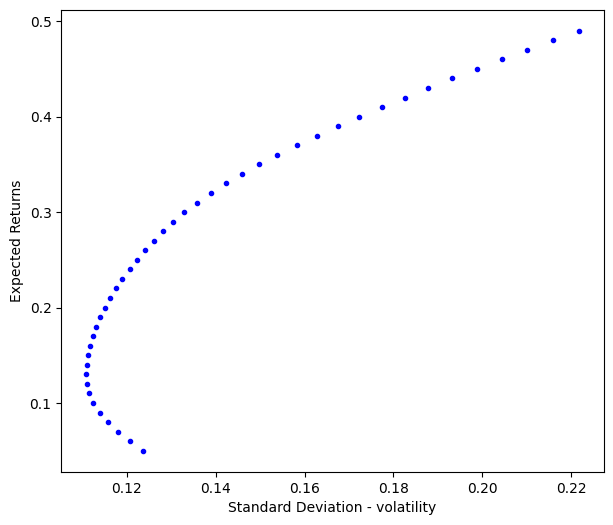

In [122]:
std_devs = [x[0] for x in points]
exp_returns = [x[1] for x in points]

plt.figure(figsize=(7,6))
plt.scatter(std_devs, exp_returns, marker='.', color='blue')
plt.xlabel('Standard Deviation - volatility')
plt.ylabel('Expected Returns')
plt.show()

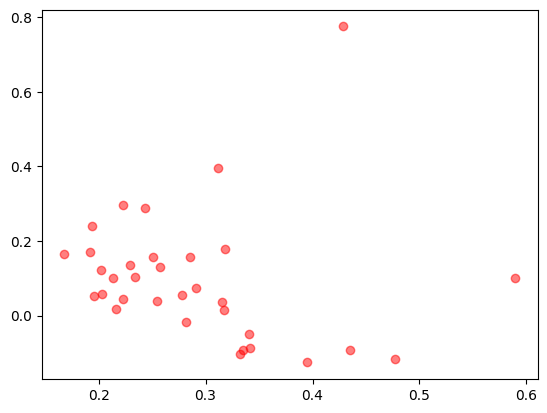

In [123]:
asset_volatilities = np.sqrt(np.diag(covariance_risk))

plt.scatter(
    asset_volatilities,
    risky_ret_annualized,
    color = "red",
    alpha = 0.5,
    marker = "o",
)

**Terza domanda: sharpe ratio e CAL:**

**1. Sharpe ratio**

In [124]:
# Definizione della funzione per lo Sharpe Ratio
def sharpe_ratio(w, ret_rate, cov, risk_free):
    ptf_ret = ret_rate.dot(w)
    ptf_std = np.sqrt(w.T.dot(cov.dot(w)))
    return -(ptf_ret - risk_free) / ptf_std

In [125]:
constraints_sharpe = [{"type": "eq", "fun": sum_weights}]

opt_sharpe = minimize(
    sharpe_ratio, # f.obiettivo
    weights0, # vettore iniziale dei pesi uniforme
    args = (risky_ret_annualized, covariance_risk, rf_annualized),
    bounds=bounds,
    constraints = constraints_sharpe,
)

sharpe_weights = opt_sharpe.x
sharpe_ret = risky_ret_annualized.dot(sharpe_weights) # rendimento atteso annualizzato del portafoglio di Sharpe
sharpe_std = np.sqrt(sharpe_weights.T.dot(covariance_risk.dot(sharpe_weights))) # volat. annualizzata del portafoglio di Sharpe
max_sharpe = (sharpe_ret - rf_annualized) / sharpe_std # valore del massimo Indice di Sharpe

print("Sharpe portfolio return: {:.3f}".format(sharpe_ret))
print("Sharpe portfolio standard dev: {:.3f}".format(sharpe_std))
print("Max sharpe ratio: {:.3f}".format(max_sharpe))

Sharpe portfolio return: 0.364
Sharpe portfolio standard dev: 0.156
Max sharpe ratio: 2.313


In [127]:
opt_sharpe.x # pesi di sharpe

array([0.00000000e+00, 2.16451082e-01, 9.26631442e-02, 6.66277320e-16,
       1.48568970e-01, 2.64324034e-01, 0.00000000e+00, 1.08705585e-15,
       4.28909120e-16, 0.00000000e+00, 0.00000000e+00, 1.37701242e-15,
       0.00000000e+00, 9.56541239e-02, 4.34303691e-16, 8.88007828e-16,
       9.84150865e-02, 7.55162926e-16, 0.00000000e+00, 0.00000000e+00,
       3.52200507e-16, 1.95789978e-16, 0.00000000e+00, 1.06071578e-15,
       8.39235593e-02, 0.00000000e+00, 0.00000000e+00, 4.07387727e-16,
       0.00000000e+00, 4.14339177e-17, 1.33316726e-15, 0.00000000e+00,
       1.76269043e-16])

- **Rendimento atteso del portafoglio di Sharpe:** 0.364 (36,4%) - Il portafoglio può guadagnare circa il 36% all'anno
- **Deviazione standard (volatilità):** 0.156 (15,6%) - Il rischio e le oscillazioni di prezzo a cui esporre il portafoglio annualmente
- **Massimo Indice di Sharpe:** 2.313 - L'efficienza complessiva del  portafoglio è molto alta e la volatilità "bassa"
- **Pesi del portafoglio di Sharpe (`sharpe_weights`):**
  `array([0.0000e+00, 2.1645e-01, 9.2663e-02, 6.6628e-16, 1.4857e-01, 2.6432e-01, 0.0000e+00, 1.0871e-15, 4.2891e-16, 0.0000e+00, 0.0000e+00, 1.3770e-15, 0.0000e+00, 9.5654e-02, 4.3430e-16, 8.8801e-16, 9.8415e-02, 7.5516e-16, 0.0000e+00, 0.0000e+00, 3.5220e-16, 1.9579e-16, 0.0000e+00, 1.0607e-15, 8.3924e-02, 0.0000e+00, 0.0000e+00, 4.0739e-16, 0.0000e+00, 4.1434e-17, 1.3332e-15, 0.0000e+00, 1.7627e-16])` La percentuale esatta di capitale che decido di investire in ogni titolo

**2. CAL**

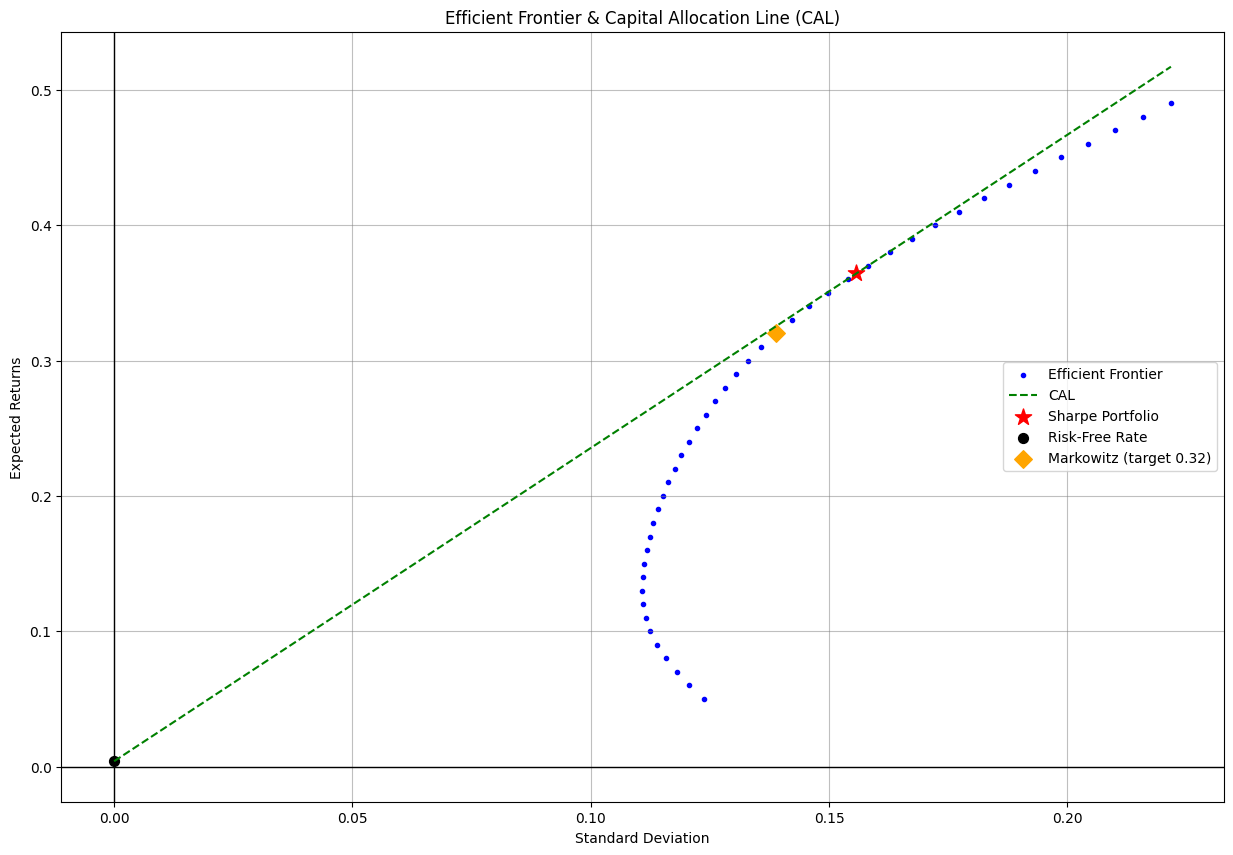

In [128]:
plt.figure(figsize=(15, 10))

plt.axhline(0, color="black", linewidth=1, linestyle="-")  # Asse X
plt.axvline(0, color="black", linewidth=1, linestyle="-")  # Asse Y

# La retta parte dal tasso risk free (0, rf_annualized) e passa per lo Sharpe Portfolio

cal_x = np.linspace(0, max(std_devs), 100)
cal_y = rf_annualized + max_sharpe * cal_x

# Plot della Frontiera, della CAL e dello Sharpe Portfolio
plt.scatter(
    std_devs,
    exp_returns,
    marker=".",
    color="blue",
    label="Efficient Frontier",
)

plt.plot(cal_x, cal_y, color="green", linestyle="--", label="CAL")

# Punto dello Sharpe Portfolio
plt.scatter(
    sharpe_std,
    sharpe_ret,
    color="red",
    marker="*",
    s=150,
    label="Sharpe Portfolio",
)

# Punto del Risk Free Rate
plt.scatter(0, rf_annualized, color="black", s=50, label="Risk-Free Rate")

plt.scatter(markowitz_std, 0.32, color="orange", marker="D", s=80, label="Markowitz (target 0.32)")

plt.xlabel("Standard Deviation")
plt.ylabel("Expected Returns")
plt.title("Efficient Frontier & Capital Allocation Line (CAL)")
plt.grid(True, linestyle="-", alpha=0.5, color="gray")
plt.legend()
plt.show()

- **Frontiera Efficiente (curva a pallini blu):** Rappresenta tutti i possibili portafogli che puoi costruire combinando i titoli a tua disposizione. La curva sale verso destra perché all'aumentare del rendimento atteso, aumenta anche il rischio.
- **CAL - Capital Allocation Line (linea verde tratteggiata):** È la linea retta che parte dal tasso privo di rischio e "tangenta" la frontiera efficiente. Mostra tutte le combinazioni possibili tra l'asset privo di rischio e il portafoglio ottimale.
- **Sharpe Portfolio (stella rossa):** È il punto di contatto esatto tra la linea verde e la curva blu. È il portafoglio migliore in assoluto perché massimizza l'Indice di Sharpe, offrendo la pendenza più ripida e il miglior compromesso tra rendimento e rischio.
- **Markowitz target 0.32 (rombo arancione):** È il portafoglio calcolato in precedenza con rendimento atteso al 32%, posizionato sulla frontiera efficiente con un rischio leggermente inferiore rispetto al portafoglio di Sharpe

- **Investitori conservativi e CAL:** Gli investitori più prudenti possono allocare una parte del proprio capitale sull'asset privo di rischio (`rf`), muovendosi verso sinistra lungo la CAL, mentre quelli che puntano a rendimenti più alti possono considerare il punto di tangenza o strategie lungo la retta.
- **Dominanza della CAL:** Qualsiasi portafoglio selezionato lungo la CAL domina rigorosamente sia i singoli titoli isolati sia i portafogli che si trovano all'interno della frontiera efficiente, assicurando così il massimo rendimento atteso per ogni singola unità di rischio sopportata.

In [129]:
for i, x in enumerate(opt_sharpe.x):
    if x > 0.0001:  # Soglia per filtrare i pesi diversi da zero (es. > 0.01%)
        print(risky_data.columns[i], f"{x:.4f} ({x * 100:.2f}%)")

ABMD 0.2165 (21.65%)
AOS 0.0927 (9.27%)
ATO 0.1486 (14.86%)
CBOE 0.2643 (26.43%)
HII 0.0957 (9.57%)
IPGP 0.0984 (9.84%)
NI 0.0839 (8.39%)


**Domanda 3: multifactor model - two factors, SP500 e Brent**

Per ogni asset stimiamo con una regressione lineare (OLS) sui rendimenti giornalieri:

$R_i = \alpha_i + \beta_{i,SP500} R_{SP500} + \beta_{i,Brent} R_{Brent} + \epsilon_i$

In [130]:
import statsmodels.api as sm
data = pd.read_csv("mark_sim.csv", index_col ="Date")

In [131]:
asset_sensitivities = {}
r_squared_values = []

In [132]:
risk_free_daily = data['rf'] / 252
all_returns = data.drop(columns=['rf']).pct_change()

for col in all_returns.columns:
    all_returns[col] = all_returns[col] - risk_free_daily

all_returns = all_returns.dropna()

returns_multimodel = all_returns.drop(columns=['SP500', 'Brent'])

X_factors = all_returns[['SP500', 'Brent']]
X_factors = sm.add_constant(X_factors)

/tmp/ipykernel_2036/2610606030.py:2: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  all_returns = data.drop(columns=['rf']).pct_change()


In [133]:
print(returns_multimodel.head()) # 34 colonne

                 AAP          ABMD       AOS       APA       ATO      CBOE  \
Date                                                                         
2014-05-09  0.017147  3.449837e-02  0.003619  0.009768 -0.001388 -0.003140   
2014-05-12  0.005539  1.528406e-02  0.031401  0.012937 -0.007737  0.014563   
2014-05-13 -0.014691 -1.688039e-02 -0.017692 -0.000223  0.001798 -0.013386   
2014-05-14 -0.002189 -7.936508e-07 -0.010053 -0.001667  0.007383 -0.013371   
2014-05-15  0.008851 -1.624194e-02  0.000210 -0.010572 -0.006736 -0.022320   

                 COP       CVX       DVA       DVN  ...      NCLH        NI  \
Date                                                ...                       
2014-05-09  0.008180 -0.000481  0.006237 -0.003663  ... -0.010382 -0.016421   
2014-05-12  0.009916  0.001679  0.004870  0.004382  ...  0.029243  0.001390   
2014-05-13  0.002933  0.004870 -0.002792  0.019566  ...  0.004323 -0.003613   
2014-05-14 -0.001399  0.004528 -0.003094 -0.009389  ... -0

In [134]:
for asset in returns_multimodel.columns:
    y_asset = returns_multimodel[asset]

    # Ora gli indici di y_asset e X_factors sono identici al 100%
    ols_model = sm.OLS(y_asset, X_factors).fit()

    asset_sensitivities[asset] = {
        'coefficients': ols_model.params,
        'pvalues': ols_model.pvalues
    }

    r_squared_values.append(ols_model.rsquared)
    print(f"Asset: {asset:<10} | R²: {ols_model.rsquared:.4f}")

mean_r_squared = np.mean(r_squared_values)
print("-" * 45)
print(f"R-Quadrato Medio: {mean_r_squared:.4f}")

Asset: AAP        | R²: 0.1216
Asset: ABMD       | R²: 0.1088
Asset: AOS        | R²: 0.4635
Asset: APA        | R²: 0.4460
Asset: ATO        | R²: 0.1714
Asset: CBOE       | R²: 0.1082
Asset: COP        | R²: 0.5252
Asset: CVX        | R²: 0.5422
Asset: DVA        | R²: 0.1910
Asset: DVN        | R²: 0.4622
Asset: ET         | R²: 0.2015
Asset: FFIV       | R²: 0.2360
Asset: FTI        | R²: 0.4071
Asset: HII        | R²: 0.2750
Asset: HSIC       | R²: 0.3122
Asset: IFF        | R²: 0.3697
Asset: IPGP       | R²: 0.2479
Asset: IRM        | R²: 0.1853
Asset: IVZ        | R²: 0.6049
Asset: JNPR       | R²: 0.2214
Asset: LNC        | R²: 0.5216
Asset: LPG        | R²: 0.1551
Asset: MOS        | R²: 0.2231
Asset: NCLH       | R²: 0.2409
Asset: NI         | R²: 0.1790
Asset: NOV        | R²: 0.3455
Asset: PRGO       | R²: 0.1190
Asset: PVH        | R²: 0.2080
Asset: QCOM       | R²: 0.2479
Asset: SEE        | R²: 0.3159
Asset: UNM        | R²: 0.4746
Asset: WU         | R²: 0.4065
Asset: X

- **Modello a due fattori (S&P 500 e Brent):** qui si calcolano le regressioni lineari per ciascun titolo, usando l'S&P 500 e il Brent come fattori di mercato.

L'analisi di regressione evidenzia un **$R^2$ Medio di $0.3007$ ($30.07\%$)**.
Ciò significa che i due fattori presi in considerazione spiegano, in media, circa un terzo delle oscillazioni di prezzo dei titoli in analisi, lasciando il restante $70\%$ al rischio specifico delle singole aziende.

1. **Titoli con Alta Sensibilità ai Fattori ($R^2 > 0.45$):**
   * **Energy / Oil & Gas:** `CVX` ($54.22\%$), `COP` ($52.52\%$), `DVN` ($46.22\%$), `APA` ($44.60\%$). La forte spiegabilità è dovuta alla doppia esposizione sia al mercato che alla materia prima (Brent).
   * **Financials & Cyclicals:** `IVZ` ($60.49\%$), `LNC` ($52.16\%$), `UNM` ($47.46\%$). La loro spiccata natura ciclica li rende estremamente dipendenti dall'andamento generale dell'S&P 500.

2. **Titoli Difensivi o Idiosincratici ($R^2 < 0.15$):**
   * Asset come `CBOE` ($10.82\%$), `ABMD` ($10.88\%$), `PRGO` ($11.90\%$) e `AAP` ($12.16\%$) mostrano un $R^2$ molto basso. La loro dinamica di prezzo è guidata prevalentemente da fattori aziendali interni o dinamiche di settore specifiche, piuttosto che dal mercato azionario generale o dal petrolio.

**Conclusione:** Il modello a 2 fattori fornisce una buona capacità esplicativa per i settori energetico e finanziario, ma necessiterebbe di ulteriori fattori (es. Tassi d'interesse/Tech) per spiegare in modo adeguato i titoli Healthcare e Difensivi.

**Scelta dei titolo rispetto al Brent**

**Strategia 1**

Il codice seguente serve a identificare ed escludere i titoli che mostrano una dipendenza statistica forte e significativa dal prezzo del Brent.

- Analizzando il `p-value` del Brent derivato dalla regressione, individuiamo le aziende i cui movimenti sono fortemente guidati dal petrolio.
- Visto che l'obiettivo è selezionare i migliori titoli in vista di un'improvvisa diminuzione del prezzo del petrolio, vogliamo ripulire il dataset escludendo tutte le società (come i titoli energetici o petroliferi) che subirebbero contraccolpi negativi diretti, isolando così i titoli più difensivi o scorrelati.

In [93]:
# Lista dei titoli da escludere in base alla significatività del Brent
to_exclude = []

for asset, data in asset_sensitivities.items():
    if asset == "SP500":
        continue

    # data['pvalues'][2] corrisponde al p-value del Brent (0: const, 1: SP500, 2: Brent)
    p_value_brent = data['pvalues'][2]

    # Se il p-value è < 0.05, la dipendenza dal Brent è statisticamente significativa
    if p_value_brent < 0.05:
        to_exclude.append(asset)

print("Titoli da escludere (dipendenza significativa dal Brent):")
print(to_exclude)

Titoli da escludere (dipendenza significativa dal Brent):
['ABMD', 'APA', 'ATO', 'CBOE', 'COP', 'CVX', 'DVN', 'ET', 'FTI', 'HSIC', 'IFF', 'IPGP', 'IVZ', 'LNC', 'LPG', 'MOS', 'NCLH', 'NOV', 'PRGO', 'PVH', 'SEE', 'UNM', 'XRAY']


/tmp/ipykernel_2036/2953129711.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_value_brent = data['pvalues'][2]


In [136]:
# Definizione dei titoli da escludere (p-value Brent < 0.05)
to_exclude = []
for asset, data in asset_sensitivities.items():
    if asset == "SP500":
        continue
    # Usiamo .iloc[2] per il terzo elemento (p-value del Brent)
    if data['pvalues'].iloc[2] < 0.05:
        to_exclude.append(asset)

chosen = []
for asset, data in asset_sensitivities.items():
    if asset == "SP500":
        continue

    if asset not in to_exclude:
        chosen.append(asset)

        proxy = yf.Ticker(asset)

        # Usiamo .iloc[0] per accedere alla prima posizione (Intercetta / Alpha)
        alpha_pct = data['coefficients'].iloc[0] * 100
        sector = proxy.info.get('sector', 'N/A')

        print(f"{asset:<8} Alpha: {alpha_pct:.5f}% | Sector: {sector}")

print("-" * 50)
print(f"Totale titoli selezionat: {len(chosen)}")

AAP      Alpha: -0.02263% | Sector: Consumer Cyclical
AOS      Alpha: 0.07296% | Sector: Industrials
DVA      Alpha: -0.02589% | Sector: Healthcare
FFIV     Alpha: 0.01059% | Sector: Technology
HII      Alpha: 0.07217% | Sector: Industrials
IRM      Alpha: 0.02432% | Sector: Real Estate
JNPR     Alpha: -0.01794% | Sector: N/A
NI       Alpha: 0.04077% | Sector: Utilities
QCOM     Alpha: -0.05040% | Sector: Technology
WU       Alpha: -0.00509% | Sector: Financial Services
--------------------------------------------------
Totale titoli selezionat: 10


- **Filtro di esclusione:** Il primo ciclo analizza tutti i titoli escludendo l'S&P 500 e verifica il `p-value` del Brent tramite `.iloc[2]`. Se il valore è inferiore a 0.05, il titolo viene aggiunto alla lista (`to_exclude`) perché troppo legato alle variazioni del petrolio.
- **Selezione dei 10 titoli:** Il secondo ciclo prende in considerazione solo i titoli che **non** fanno parte di `to_exclude` (quindi non influenzati significativamente dal Brent). Per ciascuno di essi:
  - Scarica le informazioni tramite il modulo `yfinance` (`yf.Ticker(asset)`) per estrarne il settore di appartenenza (`proxy.info.get('sector')`).
  - Estrae il coefficiente dell'intercetta (`data['coefficients'].iloc[0]`), che rappresenta l'**Alpha** (il rendimento extra del titolo depurato dai fattori di mercato e petrolio), convertendolo in percentuale (`alpha_pct`).
- **Risultato dell'output:** Vengono stampati i 10 titoli scelti (tra cui `AAP`, `AOS`, `DVA`, ecc.), ciascuno con il rispettivo valore di Alpha giornaliero e il settore di appartenenza (es. Industrials, Healthcare, Technology, Utilities, ecc.), confermando il raggiungimento del target di 10 titoli richiesto dall'esercizio.

L'Alpha (l'intercetta della regressione) misura il **rendimento extra** che un titolo riesce a generare in modo completamente indipendente dai fattori di mercato considerati, nel nostro caso l'S&P 500 e il Brent.\
Una volta esclusi i titoli troppo legati al petrolio, l'Alpha funge da **metro di giudizio e filtro di qualità** per capire quali aziende sono realmente forti:
  - **Alpha positivo** (es. `AOS` o `IRM`): Indica che l'azienda ha un business forte, sa camminare con le proprie gambe e produce valore slegato dai macro-trend. Sono i candidati ideali da inserire in portafoglio.
  - **Alpha negativo** (es. `QCOM` o `DVA`): Segnala che, pur non subendo il petrolio, il titolo storicamente rende meno di quanto ci si aspetterebbe, risultando quindi meno conveniente.

In [137]:
# Funzione per calcolare l'Indice di Sharpe - i rendimenti sono già netti (in eccesso rispetto al risk-free)
def negative_sharpe_ratio(weights, mean_returns, cov_matrix):
    portfolio_return = np.dot(weights, mean_returns)
    portfolio_std = np.sqrt(weights @ cov_matrix @ weights)
    return - (portfolio_return / portfolio_std)

In [139]:
# Filtriamo i rendimenti netti mantenendo solo i 10 titoli ottenuti
returns_strategy1 = returns_multimodel[chosen]

mean_returns_strat1 = returns_strategy1.mean() * 252
cov_matrix_strat1 = returns_strategy1.cov() * 252

num_assets_strat1 = len(chosen)

constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
bounds = tuple((0, 1) for _ in range(num_assets_strat1))
initial_weights = [1.0 / num_assets_strat1] * num_assets_strat1

# Ottimizzazione per lo Sharpe Portfolio
opt_result = minimize(
    fun = negative_sharpe_ratio,
    x0 = initial_weights,
    args =( mean_returns_strat1, cov_matrix_strat1),
    method = 'SLSQP',
    bounds = bounds,
    constraints = constraints
)

# Risultati e Pesi Ottimali
optimal_weights = opt_result.x
strat1_return = np.dot(optimal_weights, mean_returns_strat1)
strat1_std = np.sqrt(optimal_weights @ cov_matrix_strat1 @ optimal_weights)
strat1_sharpe = strat1_return / strat1_std

print("Sharpe sui titoli della strategia 1")
print(f"Rendimento Annuo Atteso: {strat1_return:.4f} ({strat1_return*100:.2f}%)")
print(f"Volatilità Annua (Std Dev): {strat1_std:.4f} ({strat1_std*100:.2f}%)")
print(f"Sharpe Ratio: {strat1_sharpe:.4f}\n")

# Tabella dei Pesi Ottimali
weights_df = pd.DataFrame({
    'Asset': chosen,
    'Peso (%)': np.round(optimal_weights * 100, 2)
}).sort_values(by='Peso (%)', ascending=False)

print(weights_df.to_string(index=False))

Sharpe sui titoli della strategia 1
Rendimento Annuo Atteso: 0.2521 (25.21%)
Volatilità Annua (Std Dev): 0.1625 (16.25%)
Sharpe Ratio: 1.5520

Asset  Peso (%)
  AOS     43.24
  HII     28.43
   NI     28.33
  AAP      0.00
 FFIV      0.00
  DVA      0.00
  IRM      0.00
 JNPR      0.00
 QCOM      0.00
   WU      0.00


- **Rendimento e Volatilità (Strategy 1):** Il rendimento annuo atteso si attesta al **25,21%** (inferiore rispetto al 36,4% del portafoglio originale senza filtri), mentre la volatilità è del **16,25%**. Questo calo è del tutto normale: eliminando i titoli petroliferi abbiamo ridotto la componente speculativa, sacrificando un po' di performance in cambio di maggiore protezione.
- **Indice di Sharpe finale (1.5520):** Rimane un valore buono, segno che il portafoglio mantiene un'ottima efficienza e continua a compensare ampiamente il rischio assunto nonostante il filtro.
- **Concentrazione estrema dei pesi:** Dei 10 titoli puliti selezionati, l'algoritmo ne ha scartati 7 azzerandone completamente il peso (`0.00`), decidendo di investire il capitale **solo su 3 azioni**:
  - **AOS:** **43,24%** del capitale
  - **HII:** **28,43%%** del capitale
  - **NI:** **28,33%** del capitale

In [140]:
chosen_strat2 = []

print("Strategia 2: titoli con sensibilità al Brent negativa (β < 0)")

for asset in to_exclude:
    brent_beta = asset_sensitivities[asset]['coefficients'].iloc[2]

    if brent_beta < 0:
        chosen_strat2.append(asset)

        # Recupero del settore in modo sicuro per evitare warning 404
        try:
            proxy = yf.Ticker(asset)
            sector = proxy.info.get('sector', 'N/A')
        except Exception:
            sector = 'N/A'

        print(f"{asset:<8} Beta Brent: {brent_beta:8.3f} | Sector: {sector}")

print("-" * 55)
print(f"Totale titoli selezionati per Strategy 2: {len(chosen_strat2)}")

Strategia 2: titoli con sensibilità al Brent negativa (β < 0)
ABMD     Beta Brent:   -0.082 | Sector: N/A
ATO      Beta Brent:   -0.043 | Sector: Utilities
CBOE     Beta Brent:   -0.069 | Sector: Financial Services
HSIC     Beta Brent:   -0.083 | Sector: Healthcare
IPGP     Beta Brent:   -0.048 | Sector: Technology
NCLH     Beta Brent:   -0.139 | Sector: Consumer Cyclical
PRGO     Beta Brent:   -0.068 | Sector: Healthcare


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: SEE"}}}


SEE      Beta Brent:   -0.054 | Sector: N/A
XRAY     Beta Brent:   -0.049 | Sector: Healthcare
-------------------------------------------------------
Totale titoli selezionati per Strategy 2: 9


- **Obiettivo della Strategy 2:** A differenza della prima strategia (che scartava i titoli legati al petrolio), questa va a ripescare tra i titoli precedentemente esclusi (*to_exclude*) solo quelli che hanno un **Beta del Brent negativo ($\beta < 0$)**.
  - Il codice scorre i titoli con dipendenza statistica significativa dal Brent.
  - Estrae il coefficiente beta del petrolio (`data['coefficients'].iloc[2]`).
  - Se il beta è **minore di zero**, il titolo viene inserito in `chosen_strat2` e viene recuperato il suo settore tramite `yfinance`.
- **La logica di copertura:** Un Beta del Brent negativo significa che **il titolo si muove in direzione opposta al petrolio**. In uno scenario in cui il prezzo del petrolio crolla improvvisamente, questi titoli tendono a beneficiare della situazione o a fare da scudo protettivo, rappresentando un ottimo hedge contro la crisi energetica.

### 💡 Motivazione Finanziaria ed Economica delle Strategie

L'utilizzo del modello multifattoriale OLS per filtrare l'universo investibile risponde a precise esigenze di gestione del rischio e di posizionamento macroeconomico:

1. **Strategy 1: Commodity-Neutral:**
   * **Logica:** Seleziona i 10 titoli la cui dipendenza dal Brent **non è statisticamente significativa** ($p\text{-value} \ge 0.05$).
   * **Obiettivo:** Ridurre l'incertezza e isolare il portafoglio da shock esogeni sul prezzo delle materie prime energetiche. È la scelta ideale per un investitore che cerca stabilità e vuole che il rendimento dipenda esclusivamente dal mercato azionario generale ($S\&P 500$) e dalla qualità specifica delle singole aziende.

2. **Strategy 2: Inverse Energy / Hedging:**
   * **Logica:** Isola i 9 titoli con dipendenza significativa dal Brent ($p\text{-value} < 0.05$) che presentano una **sensibilità negativa** ($\beta_{\text{Brent}} < 0$).
   * **Obiettivo:** Costruire un portafoglio che trae beneficio da uno scenario di calo del prezzo del petrolio (es. riduzione dei costi operativi per titoli come `NCLH` nel settore crocieristico) o che funga da copertura (*hedging*) per controbilanciare altri asset in portafoglio penalizzati da un calo dell'energia.

---
**Conclusione:** L'ottimizzazione di Markowitz tradizionale viene così arricchita da un **filtro fattoriale OLS**: l'analisi non si limita a minimizzare la varianza storica, ma consente al gestore di orientare il portafoglio in base al proprio scenario macroeconomico di riferimento.

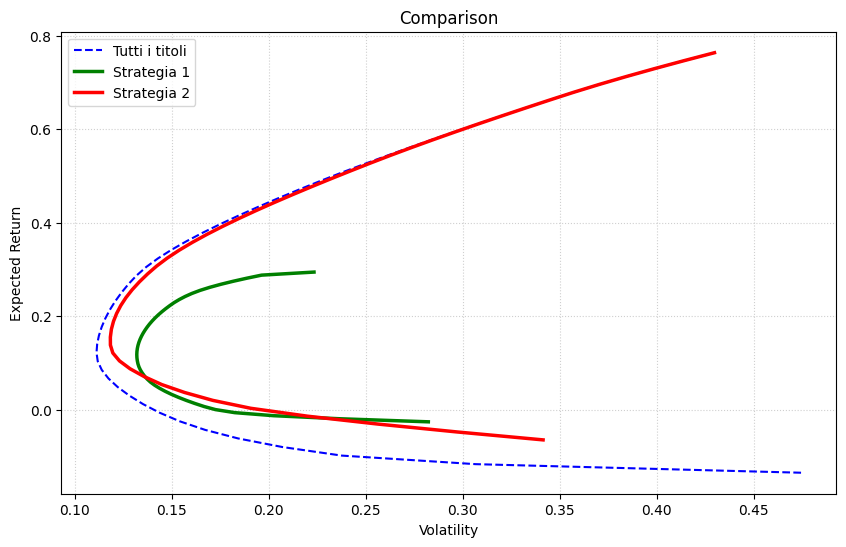

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

num_points = 50

# Fronienra completa
mean_ret_all = returns_multimodel.mean() * 252
cov_mat_all = returns_multimodel.cov() * 252
n_assets_all = len(mean_ret_all)

target_returns_all = np.linspace(mean_ret_all.min(), mean_ret_all.max(), num_points)
vols_all, rets_all = [], []
bounds_all = tuple((0, 1) for _ in range(n_assets_all))
init_w_all = [1.0 / n_assets_all] * n_assets_all

for target in target_returns_all:
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
        {'type': 'eq', 'fun': lambda w: np.dot(w, mean_ret_all) - target}
    ]
    res = minimize(lambda w: np.sqrt(w @ cov_mat_all @ w), init_w_all, method='SLSQP', bounds=bounds_all, constraints=constraints)
    if res.success:
        vols_all.append(res.fun)
        rets_all.append(target)

vols_all = np.array(vols_all)
rets_all = np.array(rets_all)


# Strategia 1
returns_s1 = returns_multimodel[chosen]
mean_ret_s1 = returns_s1.mean() * 252
cov_mat_s1 = returns_s1.cov() * 252
n_assets_s1 = len(mean_ret_s1)

target_returns_s1 = np.linspace(mean_ret_s1.min(), mean_ret_s1.max(), num_points)
vols_s1, rets_s1 = [], []
bounds_s1 = tuple((0, 1) for _ in range(n_assets_s1))
init_w_s1 = [1.0 / n_assets_s1] * n_assets_s1

for target in target_returns_s1:
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
        {'type': 'eq', 'fun': lambda w: np.dot(w, mean_ret_s1) - target}
    ]
    res = minimize(lambda w: np.sqrt(w @ cov_mat_s1 @ w), init_w_s1, method='SLSQP', bounds=bounds_s1, constraints=constraints)
    if res.success:
        vols_s1.append(res.fun)
        rets_s1.append(target)

vols_s1 = np.array(vols_s1)
rets_s1 = np.array(rets_s1)


# Strategia 2

returns_s2 = returns_multimodel[chosen_strat2]
mean_ret_s2 = returns_s2.mean() * 252
cov_mat_s2 = returns_s2.cov() * 252
n_assets_s2 = len(mean_ret_s2)

target_returns_s2 = np.linspace(mean_ret_s2.min(), mean_ret_s2.max(), num_points)
vols_s2, rets_s2 = [], []
bounds_s2 = tuple((0, 1) for _ in range(n_assets_s2))
init_w_s2 = [1.0 / n_assets_s2] * n_assets_s2

for target in target_returns_s2:
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
        {'type': 'eq', 'fun': lambda w: np.dot(w, mean_ret_s2) - target}
    ]
    res = minimize(lambda w: np.sqrt(w @ cov_mat_s2 @ w), init_w_s2, method='SLSQP', bounds=bounds_s2, constraints=constraints)
    if res.success:
        vols_s2.append(res.fun)
        rets_s2.append(target)

vols_s2 = np.array(vols_s2)
rets_s2 = np.array(rets_s2)


# Comparazione
plt.figure(figsize=(10, 6))
plt.plot(vols_all, rets_all, 'b--', label='Tutti i titoli', linewidth=1.5)
plt.plot(vols_s1, rets_s1, 'g-', label='Strategia 1', linewidth=2.5)
plt.plot(vols_s2, rets_s2, 'r-', label='Strategia 2', linewidth=2.5)

plt.title('Comparison', fontsize=12)
plt.xlabel('Volatility', fontsize=10)
plt.ylabel('Expected Return', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='best')
plt.show()

- **Tutti i titoli (Linea blu tratteggiata):** Rappresenta la frontiera teorica calcolata sull'intero paniere disponibile. È quella che si spinge più a sinistra verso il basso in termini di rischio minimo, offrendo lo spettro completo delle combinazioni possibili.
- **Strategia 1 (Linea verde):** Si posiziona su livelli di volatilità intermedi e copre un intervallo di rendimento atteso più moderato (fino a circa 0.30). Escludendo i titoli petroliferi, delinea un profilo di portafoglio più bilanciato e difensivo.
- **Strategia 2 (Linea rossa):** Sfruttando i titoli con Beta del Brent negativo, la frontiera si estende in modo marcato verso l'alto raggiungendo rendimenti attesi molto elevati (oltre 0.70), sebbene a fronte di una volatilità decisamente superiore (fino a oltre 0.40).

### 📝 In conclusione:
#### 1. Selezione e criteri metodologici
L'obiettivo principale dell'analisi è stato strutturare strategie di investimento capaci di rispondere a specifici scenari di mercato:

1. **Capacità esplicativa del modello ($R^2$):** è stata analizzata la bontà di adattamento dei due fattori, registrando un $R^2$ medio del $30.07\%$. I titoli con $R^2$ più elevato (es. *CVX, COP, IVZ*) hanno evidenziato una forte componente sistemica e ciclica, mentre quelli con $R^2$ basso (es. *CBOE, ABMD*) sono risultati guidati prevalentemente da dinamiche e rischi specifici (*idiosincratici*).
2. **Parametri di regressione ($\alpha$ e $\beta_{\text{Brent}}$):**
   * è stata posta attenzione all'$\alpha$, indicatore del rendimento extra generato dal titolo in modo indipendente dai fattori di mercato e dalle materie prime;
   * sono stati valutati i coefficienti di sensibilità al petrolio ($\beta_{\text{Brent}}$) e i relativi $p\text{-value}$ per discriminare i titoli resilienti da quelli fortemente esposti agli shock energetici.

---

#### 2. Confronto delle Strategie

- **Strategy 1 (Commodity-Neutral):**
  * *Selezione:* titoli con dipendenza non significativa dal Brent ($p\text{-value}_{\text{Brent}} \ge 0.05$), tra cui `AOS`, `HII`, `NI`, `FFIV`, `IRM`, `WU`, `DVA`, `AAP`, `JNPR` e `QCOM`.
  * *Obiettivo:* immunizzare il portafoglio dalle oscillazioni del petrolio, concentrandosi sulla qualità propria degli asset;
  * *Risultato:* offre un profilo di portafoglio più bilanciato, difensivo e con una volatilità controllata (16,25%), a fronte di un rendimento atteso moderato ma associato a un ottimo Indice di Sharpe (1.5520).

- **Strategy 2 (Inverse Energy/Hedging):**
  * *Selezione:* titoli con dipendenza significativa dal Brent ($p\text{-value}_{\text{Brent}} < 0.05$) ma caratterizzati da un **Beta del petrolio negativo ($\beta_{\text{Brent}} < 0$)**, tra cui `NCLH`, `HSIC`, `ABMD`, `CBOE`, `PRGO`, `SEE`, `IPGP`, `XRAY` e `ATO`.
  * *Obiettivo:* sfruttare asset che si muovono in direzione opposta al petrolio per fungere da copertura (*hedge*) o beneficiare di un calo dei costi energetici.
  * *Risultato:* grazie a questa dinamica inversa, la frontiera si estende in modo marcato verso l'alto, raggiungendo rendimenti attesi molto elevati (oltre il $70\%$), sebbene a fronte di una volatilità superiore.

---

#### 💡 Conclusione
Mentre la **Strategy 1** si dimostra ideale per un profilo più conservativo e orientato alla stabilità con un eccellente rapporto rischio-rendimento, la **Strategy 2** evidenzia come l'impiego di titoli con sensibilità inversa al Brent ($\beta < 0$) rappresenti uno strumento di copertura efficace capace di amplificare i rendimenti attesi in determinati contesti di mercato.